<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

Počet objednávok: 196
Najstaršia objednávka: 1996-07-04 00:00:00
Najnovšia objednávka: 1997-02-12 00:00:00

Počet objednávok podľa roku:
orderdate
1996    152
1997     44
Name: count, dtype: int64

Počet objednávok podľa mesiaca:
orderdate
1996-07    22
1996-08    25
1996-09    23
1996-10    26
1996-11    25
1996-12    31
1997-01    33
1997-02    11
Freq: M, Name: count, dtype: int64


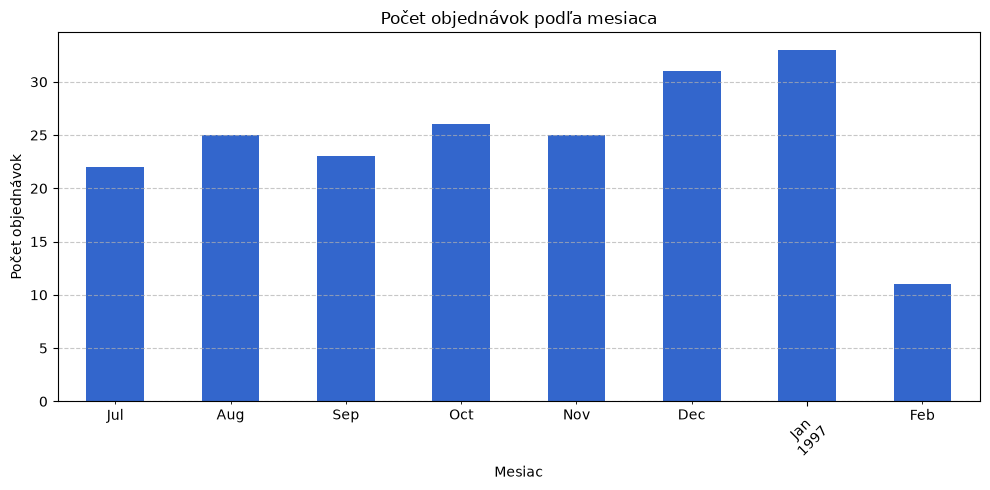

In [ ]:
# Vaše riešenie
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('orders.csv', parse_dates=['orderdate'])

print(f"Počet objednávok: {len(df)}")
print(f"Najstaršia objednávka: {df['orderdate'].min()}")
print(f"Najnovšia objednávka: {df['orderdate'].max()}")

print("\nPočet objednávok podľa roku:")
print(df['orderdate'].dt.year.value_counts().sort_index())

monthly_orders = df['orderdate'].dt.to_period('M').value_counts().sort_index()
print("\nPočet objednávok podľa mesiaca:")
print(monthly_orders)

plt.figure(figsize=(10, 5))
monthly_orders.plot(kind='bar', color='#3366cc')
plt.title('Počet objednávok podľa mesiaca')
plt.xlabel('Mesiac')
plt.ylabel('Počet objednávok')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [ ]:
# Vaše riešenie
hranica = '1997-01-01'

historical_orders = df[df['orderdate'] < hranica]
new_orders = df[df['orderdate'] >= hranica]

print("Historické objednávky:", len(historical_orders))
print("Novšie objednávky:", len(new_orders))

Historické objednávky: 152
Novšie objednávky: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [ ]:
import psycopg2
from psycopg2.extensions import ISOLATION_LEVEL_AUTOCOMMIT
from sqlalchemy import create_engine, text

# --- 1. NASTAVENIE PRIPOJENIA ---
# Nezabudni prepísať 'TVOJE_NOVE_HESLO' na heslo, ktoré si si práve zmenil v pgAdmin (napr. '1234')
uzivatel = 'postgres'
heslo = 'root' 
host = 'localhost'
port = '5432'
nova_databaza = 'orders_practice' # Názov databázy podľa pomôcky v zadaní

# Najskôr sa pripojíme do predvolenej databázy 'postgres'
pripojenie = psycopg2.connect(
    dbname='postgres', user=uzivatel, password=heslo, host=host, port=port
)
# Zapneme AUTOCOMMIT
pripojenie.set_isolation_level(ISOLATION_LEVEL_AUTOCOMMIT)
kurzor = pripojenie.cursor()

kurzor.execute(f"SELECT 1 FROM pg_catalog.pg_database WHERE datname = '{nova_databaza}'")
if not kurzor.fetchone():
    kurzor.execute(f"CREATE DATABASE {nova_databaza};")

# Zatvoríme toto prvé pripojenie
kurzor.close()
pripojenie.close()

engine = create_engine(f'postgresql+psycopg2://{uzivatel}:{heslo}@{host}:{port}/{nova_databaza}')

with engine.connect() as spojenie:
    spojenie.execute(text("DROP TABLE IF EXISTS orders;"))
    
    spojenie.execute(text("""
        CREATE TABLE orders (
            orderid INT PRIMARY KEY,
            customerid VARCHAR(50),
            employeeid INT,
            orderdate DATE,
            shipperid INT
        );
    """))
    spojenie.commit()

# Nahráme všetky záznamy z 'df' do databázy pomocou to_sql s if_exists="append"
df.to_sql('orders', con=engine, if_exists='append', index=False)

print("Tabuľka orders bola vytvorená a naplnená.")

Tabuľka orders bola vytvorená a naplnená.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [11]:
# Vaše riešenie
pocet_objednavok = len(historical_orders)

pocet_zakaznikov = historical_orders['customerid'].nunique()

objednavky_dopravca_3 = (historical_orders['shipperid'] == 3).sum()

percento_dopravca_3 = (objednavky_dopravca_3 / pocet_objednavok) * 100
percento_zaokruhlene = round(percento_dopravca_3, 2)

print("Objednávok:", pocet_objednavok)
print("Zákazníkov:", pocet_zakaznikov)
print("Dopravca 3 (%):", percento_zaokruhlene)

Objednávok: 152
Zákazníkov: 66
Dopravca 3 (%): 38.16


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [12]:
# Vaše riešenie
import pandas as pd
from sqlalchemy import text

cutoff_datum = '1997-01-01'
SAMPLE_SIZE = 44

sql_dotaz = text("""
    SELECT * 
    FROM orders 
    WHERE orderdate >= :cutoff 
    ORDER BY orderdate, orderid 
    LIMIT :limit
""")

with engine.connect() as spojenie:
    simulacne_objednavky = pd.read_sql(
        sql_dotaz, 
        con=spojenie, 
        params={"cutoff": cutoff_datum, "limit": SAMPLE_SIZE}
    )

print("Objednávok v simulácii:", len(simulacne_objednavky))

Objednávok v simulácii: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [13]:
# Vaše riešenie
import time

EVENT_DELAY_SEC = 0.04      
MICRO_WINDOW_SEC = 0.30 

stream_pocet = 0
stream_dopravca_3 = 0
stream_historia = [] #(čas, počet, percento)

mb_pocet = 0
mb_dopravca_3 = 0
mb_aktualna_davka = []     
mb_historia = [] #(čas, počet, percento)

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [14]:
start_simulacie = time.time()
start_okna = start_simulacie

for index, riadok in simulacne_objednavky.iterrows():
    time.sleep(EVENT_DELAY_SEC)
    aktualny_cas = time.time() - start_simulacie
    dopravca = riadok['shipperid']
    
    stream_pocet += 1
    if dopravca == 3:
        stream_dopravca_3 += 1
        
    stream_percento = (stream_dopravca_3 / stream_pocet) * 100
    stream_historia.append((aktualny_cas, stream_pocet, stream_percento))
    
    mb_aktualna_davka.append(dopravca)
    
    if (time.time() - start_okna) >= MICRO_WINDOW_SEC:
        # Okno uplynulo -> spracujeme všetko, čo sa v dávke nazbieralo
        mb_pocet += len(mb_aktualna_davka)
        mb_dopravca_3 += mb_aktualna_davka.count(3)
        
        mb_percento = (mb_dopravca_3 / mb_pocet) * 100
        mb_historia.append((aktualny_cas, mb_pocet, mb_percento))
        
        mb_aktualna_davka = []
        start_okna = time.time()

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [15]:
# Vaše riešenie
if len(mb_aktualna_davka) > 0:
    aktualny_cas = time.time() - start_simulacie
    mb_pocet += len(mb_aktualna_davka)
    mb_dopravca_3 += mb_aktualna_davka.count(3)
    
    mb_percento = (mb_dopravca_3 / mb_pocet) * 100
    mb_historia.append((aktualny_cas, mb_pocet, mb_percento))
    mb_aktualna_davka = []

batch_pocet = len(simulacne_objednavky)
batch_dopravca_3 = (simulacne_objednavky['shipperid'] == 3).sum()
batch_percento = (batch_dopravca_3 / batch_pocet) * 100

print("Počet objednávok:", batch_pocet)
print("Batch (%):", round(batch_percento, 2))
print("Micro-batch (%):", round(mb_percento, 2))
print("Streaming (%):", round(stream_percento, 2))

Počet objednávok: 44
Batch (%): 22.73
Micro-batch (%): 22.73
Streaming (%): 22.73


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

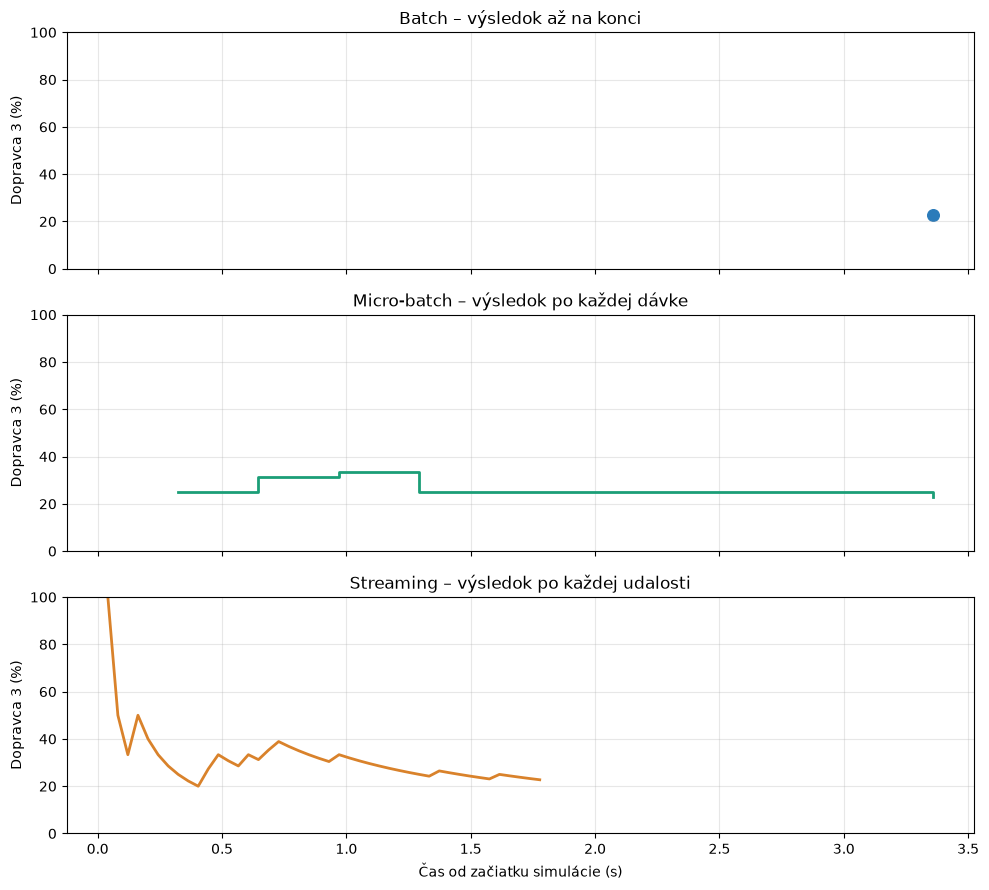

In [16]:
# Vaše riešenie
import matplotlib.pyplot as plt

stream_casy = [zaznam[0] for zaznam in stream_historia]
stream_percenta = [zaznam[2] for zaznam in stream_historia]

mb_casy = [zaznam[0] for zaznam in mb_historia]
mb_percenta = [zaznam[2] for zaznam in mb_historia]

batch_cas = max(stream_casy[-1], mb_casy[-1])

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True, sharey=True)

ax1.scatter([batch_cas], [batch_percento], color='#2b7bba', s=70)
ax1.set_title('Batch – výsledok až na konci')
ax1.set_ylabel('Dopravca 3 (%)')
ax1.set_ylim(0, 100)
ax1.grid(True, alpha=0.3)

ax2.step(mb_casy, mb_percenta, where='post', color='#1b9e77', linewidth=2)
ax2.set_title('Micro-batch – výsledok po každej dávke')
ax2.set_ylabel('Dopravca 3 (%)')
ax2.grid(True, alpha=0.3)

ax3.plot(stream_casy, stream_percenta, color='#d9822b', linewidth=2)
ax3.set_title('Streaming – výsledok po každej udalosti')
ax3.set_ylabel('Dopravca 3 (%)')
ax3.set_xlabel('Čas od začiatku simulácie (s)')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

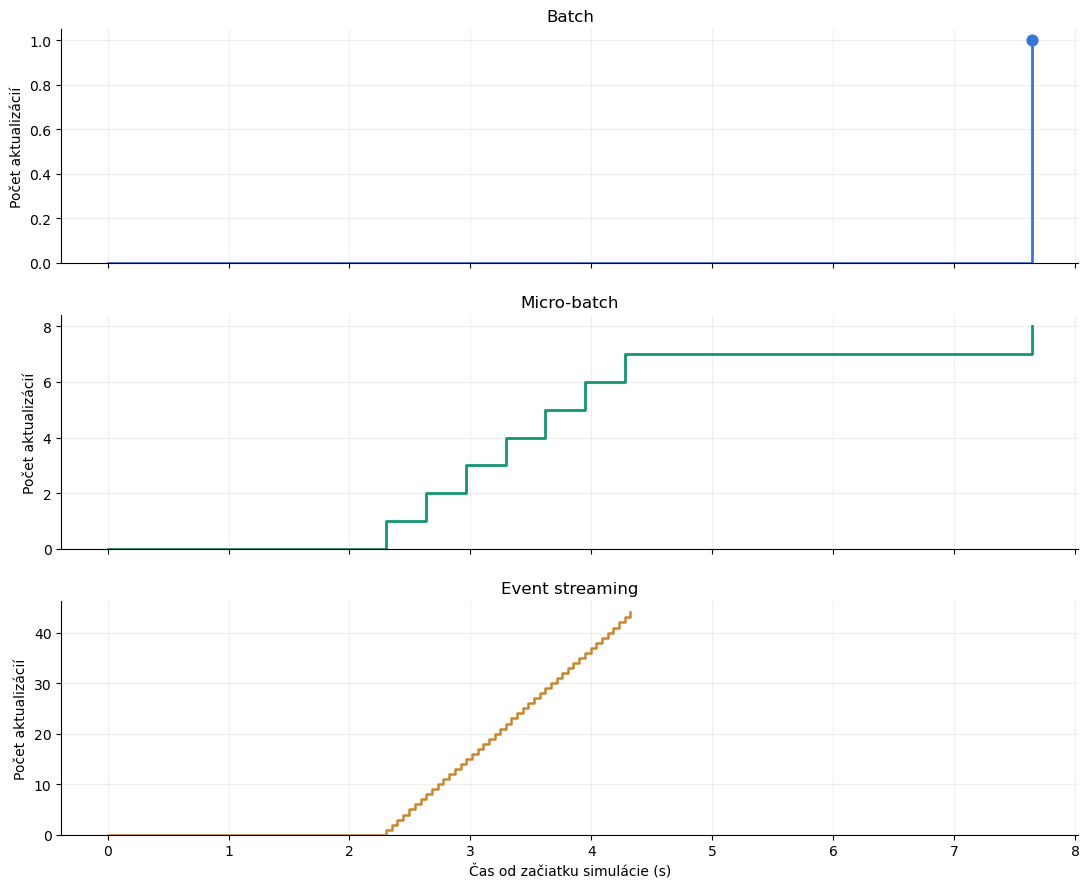

        Prístup Prvý výsledok (s)
          Batch             7.645
    Micro-batch             2.303
Event streaming             2.303


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

batch_x = [0, batch_cas]
batch_y = [0, 1]

mb_x = [0] + mb_casy
mb_y = list(range(len(mb_casy) + 1))

stream_x = [0] + stream_casy
stream_y = list(range(len(stream_casy) + 1))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True, sharey=False)

ax1.step(batch_x, batch_y, where='post', color='#2b7bba', linewidth=1.5)
ax1.scatter([batch_cas], [1], color='#2b7bba', s=60)
ax1.set_title('Batch')
ax1.set_ylabel('Počet aktualizácií')
ax1.grid(True, alpha=0.3)

ax2.step(mb_x, mb_y, where='post', color='#1b9e77', linewidth=1.8)
ax2.set_title('Micro-batch')
ax2.set_ylabel('Počet aktualizácií')
ax2.grid(True, alpha=0.3)

ax3.step(stream_x, stream_y, where='post', color='#d9822b', linewidth=1.8)
ax3.set_title('Event streaming')
ax3.set_ylabel('Počet aktualizácií')
ax3.set_xlabel('Čas od začiatku simulácie (s)')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

tabulka = pd.DataFrame({
    'Prístup': ['Batch', 'Micro-batch', 'Event streaming'],
    'Prvý výsledok (s)': [
        round(batch_cas, 3),
        round(mb_casy[0], 3),
        round(stream_casy[0], 3)
    ]
})

print(tabulka.to_string(index=False))

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>